# Brazil: well-level production from ANP

ANP publishes monthly production for every Brazilian well as bulk zips on
gov.br — yearly archives for 2005–2020, monthly ones for 2021–2023 (from 2024
on the data only exists in ANP's interactive [CDP app](https://cdp.anp.gov.br/),
so fetching a later year raises a pointed error).

One month arrives as **three CSVs**: terra (onshore), mar (offshore) and
pré-sal — and the pré-sal file is a *subset* of mar. Ingest resolves that
overlap for you, as shown below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

import ogprod

# Categorical palette in fixed slot order (colorblind-safe adjacency)
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "figure.figsize": (9, 4),
    "font.size": 11,
})

# Raw files kept for inspection; notebooks run with cwd = notebooks/.
DATA = Path("../data")
DATA.mkdir(exist_ok=True)

# The store lives in ~/.local/share/ogprod/store unless $OGPROD_STORE says otherwise.
db = ogprod.Store()
db

Store('/Users/mralbu/.local/share/ogprod/store')

## Ingest June 2023

`db.ingest("anp", year=2023, month=6)` would fetch, parse and upsert in one
call. Here we keep the raw CSVs on disk (to look inside them below), so we
download them with the ANP connector and hand them to `ingest(files=...)`.
Either way the connector orders the files so the pré-sal rows *restate*
their identical mar counterparts instead of adding to them — no
double-counting, whatever order the files come in. The first ANP ingest also
pulls the well cadastre (~31k wells with coordinates).

In [2]:
from ogprod.sources import anp

paths = sorted((DATA / "anp").glob("2023_06_*.csv"))
if not paths:
    paths = anp.ANP().fetch(DATA / "anp", year=2023, month=6)
print(db.ingest("anp", files=paths))
[path.name for path in paths]

anp: 28,124 production rows 2023-06..2023-06 in 1 partition(s); entities: 31,310


['2023_06_producao_Mar.csv',
 '2023_06_producao_Presal.csv',
 '2023_06_producao_Terra.csv']

The store hands back one clean canonical frame for the month — no
source-specific file juggling:

In [3]:
brazil = db.production(source="anp", start="2023-06-01", end="2023-06-01")
brazil.head()

,source,entity_type,entity_id,entity_name,field,basin,region,operator,period,product,volume
0,anp,well,1-ALV-11-BA,1-ALV-11-BA,CABURÉ LESTE,Recôncavo,Bahia,Alvopetro,2023-06-01,condensate,0.024802
1,anp,well,1-ALV-11-BA,1-ALV-11-BA,CABURÉ LESTE,Recôncavo,Bahia,Alvopetro,2023-06-01,gas,0.000000
2,anp,well,1-ALV-11-BA,1-ALV-11-BA,CABURÉ LESTE,Recôncavo,Bahia,Alvopetro,2023-06-01,oil,0.000000
3,anp,well,1-ALV-11-BA,1-ALV-11-BA,CABURÉ LESTE,Recôncavo,Bahia,Alvopetro,2023-06-01,water,0.057235
4,anp,well,1-ALV-5-BA,1-ALV-5-BA,MURUCUTUTU,Recôncavo,Bahia,Alvopetro,2023-06-01,condensate,56.707906


## Pré-sal is a subset of mar — ingest already resolved it

Concatenating all three CSVs by hand would double-count pre-salt wells.
Parsing each raw file with the connector shows the parts; the store holds
terra + mar once (the pré-sal share of offshore oil can still be computed
from the raw parts):

In [4]:
BBL_D = lambda v: ogprod.convert(v, "m3", "bbl") / 30 / 1e6  # June has 30 days

parts = {p.name.rsplit("_", 1)[-1].removesuffix(".csv").lower(): anp.ANP().parse(p)
         for p in paths}
oil = {name: part[part["product"] == "oil"]["volume"].sum() for name, part in parts.items()}
for name in ("terra", "mar", "presal"):
    print(f"{name:>7}: {BBL_D(oil[name]):.2f} M bbl/d")

store_oil = brazil[brazil["product"] == "oil"]["volume"].sum()
print(f"\nnaive sum of all 3 CSVs:    {BBL_D(sum(oil.values())):.2f} M bbl/d (double-counts)")
print(f"store total (terra + mar):  {BBL_D(store_oil):.2f} M bbl/d")
print(f"pré-sal share of offshore oil: {oil['presal'] / oil['mar']:.0%}")

  terra: 0.07 M bbl/d
    mar: 3.29 M bbl/d
 presal: 2.55 M bbl/d

naive sum of all 3 CSVs:    5.91 M bbl/d (double-counts)
store total (terra + mar):  3.36 M bbl/d
pré-sal share of offshore oil: 78%


## Where the oil comes from

A ranked horizontal bar wants a single hue — magnitude is the message, the
axis carries the values.

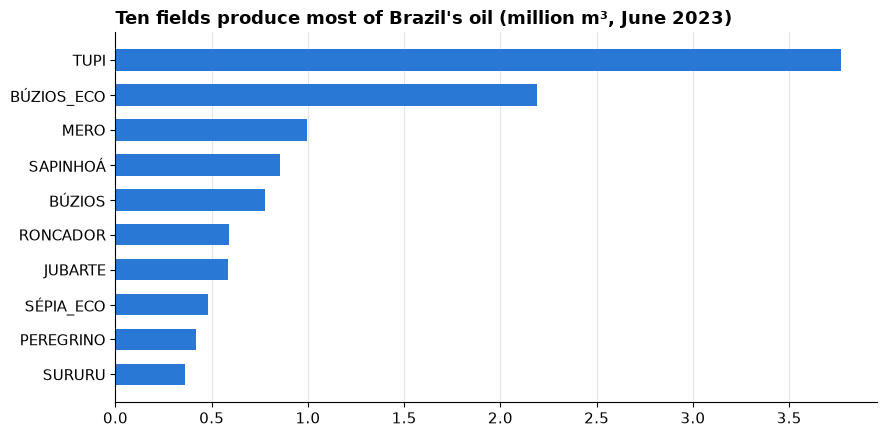

In [5]:
top = (brazil[brazil["product"] == "oil"]
       .groupby("field")["volume"].sum()
       .nlargest(10)
       .sort_values())

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top.values / 1e6, color=PALETTE[0], height=0.62)
ax.set_title("Ten fields produce most of Brazil's oil (million m³, June 2023)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

Well-level granularity means you can go as fine as a single wellbore:

In [6]:
tupi = brazil[(brazil["field"] == "TUPI") & (brazil["product"] == "oil")]
print(f"TUPI: {len(tupi)} producing wells, "
      f"best well {BBL_D(tupi['volume'].max()) * 1e3:.1f} k bbl/d, "
      f"median {BBL_D(tupi['volume'].median()) * 1e3:.1f} k bbl/d")
tupi.nlargest(5, "volume")[["entity_id", "field", "basin", "volume"]]

TUPI: 58 producing wells, best well 31.4 k bbl/d, median 15.0 k bbl/d


,entity_id,field,basin,volume
26958,7-TUP-121DA-RJS,TUPI,Santos,149552.954824
28026,9-LL-20D-RJS,TUPI,Santos,136062.251511
28004,9-LL-12D-RJS,TUPI,Santos,115968.468786
27344,8-LL-87D-RJS,TUPI,Santos,107939.735992
19920,7-LL-66-RJS,TUPI,Santos,106493.483103
